# 04 — Phân tích nhãn trả/hoàn hàng (ground truth của bộ sinh dữ liệu)

Dữ liệu là mẫu nhỏ `labels_small.parquet` (7.343 dòng, sao chép từ lần sinh `small` của generator, đã commit trong `notebooks/data/`).
Mỗi dòng là một dòng đơn hàng: nhãn `label` (1 = trả hoặc hoàn trong cửa sổ 30 ngày), ngày giao `delivered_at` và thời điểm nhãn có thể dùng được `label_available_at`.

Câu hỏi: nhãn mất cân bằng đến đâu, và độ trễ giữa giao hàng với lúc nhãn có sẵn là bao nhiêu (quan trọng cho việc tránh rò rỉ nhãn khi chia train/test).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
EVIDENCE = ROOT / "docs" / "evidence"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
labels = pd.read_parquet(ROOT / "notebooks" / "data" / "labels_small.parquet")
print(labels.shape)
labels.dtypes.to_frame("kiểu").join(labels.isna().sum().rename("thiếu"))

(7343, 4)


,kiểu,thiếu
order_line_id,str,0
label,int8,0
delivered_at,"datetime64[us, UTC]",0
label_available_at,"datetime64[us, UTC]",0


In [3]:
prevalence = labels["label"].mean()
print(
    f"{len(labels):,} dòng | tỷ lệ nhãn dương: {prevalence:.3%} ({int(labels['label'].sum()):,} dòng)"
)
print("dòng đơn hàng trùng order_line_id:", int(labels["order_line_id"].duplicated().sum()))

7,343 dòng | tỷ lệ nhãn dương: 12.257% (900 dòng)
dòng đơn hàng trùng order_line_id: 0


## Độ trễ nhãn

`label_available_at - delivered_at` là bao lâu sau khi giao thì biết đơn có bị trả hay không.

In [4]:
delay = (labels["label_available_at"] - labels["delivered_at"]).dt.total_seconds() / 86400
print("độ trễ nhãn (ngày): các giá trị khác nhau =", delay.round(6).unique().tolist())
assert delay.nunique() == 1 and round(delay.iloc[0]) == 30

độ trễ nhãn (ngày): các giá trị khác nhau = [30.0]


Độ trễ **đúng 30 ngày với mọi dòng** (cửa sổ cố định của generator, không phân phối), nên không cần biểu đồ. Hệ quả: khi huấn luyện, chỉ được dùng
nhãn của đơn đã giao cách ít nhất 30 ngày, nếu không sẽ rò rỉ nhãn tương lai vào tập huấn luyện.

## Nhãn theo đơn hàng, không chỉ theo dòng

`order_line_id` có dạng `ORD-<kênh>-<đơn>-<dòng>`. Một đơn có thể có nhiều dòng với nhãn khác nhau.

4,994 đơn; số dòng mỗi đơn: {1: 3116, 2: 1480, 3: 334, 4: 55, 5: 9}
trạng thái
toàn âm       4133
lẫn lộn        457
toàn dương     404


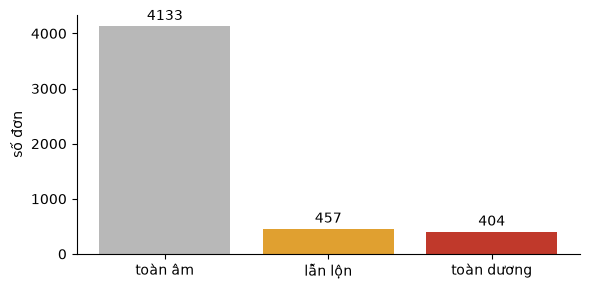

In [5]:
labels["order_id"] = labels["order_line_id"].str.rsplit("-", n=1).str[0]
orders = labels.groupby("order_id")["label"].agg(dòng="size", dương="sum")
orders["trạng thái"] = np.select(
    [orders["dương"] == 0, orders["dương"] == orders["dòng"]], ["toàn âm", "toàn dương"], "lẫn lộn"
)
print(
    f"{len(orders):,} đơn; số dòng mỗi đơn: {orders['dòng'].value_counts().sort_index().to_dict()}"
)
print(orders["trạng thái"].value_counts().to_string())
fig, ax = plt.subplots(figsize=(6, 3))
counts = orders["trạng thái"].value_counts().reindex(["toàn âm", "lẫn lộn", "toàn dương"])
bars = ax.bar(counts.index, counts.values, color=["#b8b8b8", "#e0a030", "#c0392b"])
ax.bar_label(bars, padding=2)
ax.set_ylabel("số đơn")
plt.tight_layout()
plt.show()

457 đơn có nhãn **lẫn lộn** giữa các dòng: nhãn gắn ở mức dòng, không phải mức đơn. Vì vậy khi chia train/test nên nhóm theo đơn
(cùng đơn cùng phía), nếu không các dòng cùng đơn, cùng ngày giao, rơi cả hai bên và làm điểm đánh giá lạc quan.

## Tỷ lệ nhãn dương theo ngày giao

Tất cả 7.343 dòng giao trong tháng 01/2026 (29 ngày có đơn), nên xem theo ngày.

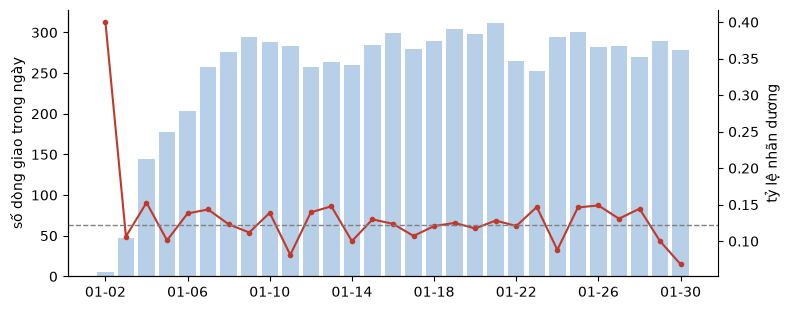

,dòng,tỷ_lệ
delivered_at,,
2026-01-02,5,0.400000
2026-01-03,47,0.106383
2026-01-04,144,0.152778


In [6]:
daily = labels.groupby(labels["delivered_at"].dt.date)["label"].agg(dòng="size", tỷ_lệ="mean")
fig, ax1 = plt.subplots(figsize=(8, 3.2))
ax1.bar(range(len(daily)), daily["dòng"], color="#b8cfe8")
ax1.set_ylabel("số dòng giao trong ngày")
ax1.set_xticks(range(0, len(daily), 4), [str(d)[5:] for d in daily.index[::4]])
ax2 = ax1.twinx()
ax2.plot(range(len(daily)), daily["tỷ_lệ"], color="#c0392b", marker="o", ms=3)
ax2.axhline(prevalence, color="gray", ls="--", lw=1)
ax2.set_ylabel("tỷ lệ nhãn dương")
ax2.spines["right"].set_visible(True)
plt.tight_layout()
plt.show()
daily.sort_values("dòng").head(3)

Tỷ lệ dương quanh mức chung (đường đứt) và khá ổn định ở các ngày có khoảng 250–310 dòng. Ngày ít dòng nhất (5 dòng) có tỷ lệ 40%: đó là nhiễu
của mẫu nhỏ ở biên khoảng thời gian, không phải tín hiệu. Đây là dữ liệu mô phỏng của generator, không phải số thật của một sàn.